# Team T085 · Section E · Project 26
Phase 1: Machine Learning

The expanded run reuses the previously inspected test partition. Training-only selection and validation-only robustness are preserved; this is not a fresh independent holdout.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').exists(), 'Start Jupyter in the project folder.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
TABLES=ROOT/'results/tables'
FIGURES=ROOT/'results/figures'
def table(name): return pd.read_csv(TABLES/name)
def figure(name): display(Image(filename=str(FIGURES/name)))


## Data and literature
Owner: Role 1. Read reports/literature_review.md for EM, isolation and precision-recall background. Models fit known legitimate training records; labels filter that population but never enter the model features. Training EDA covers quality, base rates, Amount, Time and V1-V28.

In [2]:
from src.data import load_raw, load_split_indices
import yaml
cfg=yaml.safe_load((ROOT/'configs/config.yaml').read_text())
path=ROOT/'data/raw/creditcard.csv'
raw=load_raw(path)
parts=load_split_indices(raw,ROOT/'data/processed/split_indices.npz',path,cfg['split_fractions'])
display(table('split_summary.csv').drop(columns='index_sha256'))
print(json.loads((ROOT/'data/processed/split_manifest.json').read_text())['quality'])
print('Loaded exact frozen row membership from split_indices.npz.')

,split,rows,fraud,legitimate,base_rate,time_min,time_max
0,train,170888,360,170528,0.002107,0.0,120396.0
1,validation,56958,57,56901,0.001001,120397.0,145248.0
2,test,56961,75,56886,0.001317,145249.0,172792.0


{'rows': 284807, 'columns': 31, 'missing_cells': 0, 'exact_duplicate_rows': 1081, 'duplicate_policy': 'Retained; tied timestamps stay in one partition.'}
Loaded exact frozen row membership from split_indices.npz.


In [3]:
train=parts['train']
display(train.describe().round(3))
assert train.Time.max()<parts['validation'].Time.min()
assert parts['validation'].Time.max()<parts['test'].Time.min()
with np.load(ROOT/'data/processed/split_indices.npz') as z:
    np.testing.assert_array_equal(z['train_legitimate'],train.index[train.Class==0])

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,...,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000,170888.000
mean,61093.302,-0.170,0.041,0.493,0.117,-0.176,0.058,-0.081,0.032,0.019,...,-0.028,-0.084,-0.022,0.009,0.092,0.013,0.002,0.002,87.336,0.002
std,27829.551,1.851,1.611,1.383,1.372,1.339,1.295,1.209,1.228,1.152,...,0.744,0.667,0.585,0.599,0.466,0.491,0.392,0.307,245.951,0.046
min,0.000,-56.408,-72.716,-33.681,-5.520,-42.148,-26.161,-43.557,-73.217,-13.434,...,-34.830,-10.933,-44.808,-2.837,-10.295,-2.605,-22.566,-11.711,0.000,0.000
25%,41217.000,-0.987,-0.539,-0.065,-0.743,-0.829,-0.691,-0.586,-0.163,-0.660,...,-0.231,-0.547,-0.170,-0.332,-0.196,-0.330,-0.065,-0.027,5.480,0.000
50%,60776.000,-0.184,0.110,0.623,0.124,-0.226,-0.203,-0.032,0.057,-0.079,...,-0.054,-0.067,-0.036,0.059,0.136,-0.059,0.009,0.021,21.900,0.000
75%,78623.000,1.184,0.804,1.297,0.938,0.374,0.449,0.463,0.351,0.641,...,0.128,0.363,0.099,0.416,0.399,0.273,0.090,0.078,76.722,0.000
max,120396.000,2.439,22.058,9.383,16.875,34.802,22.529,36.677,20.007,15.595,...,27.203,10.503,19.003,4.023,7.520,3.517,12.152,33.848,19656.530,1.000


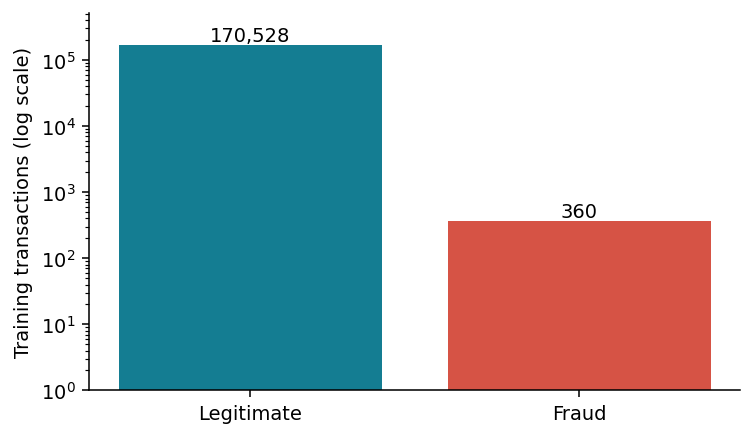

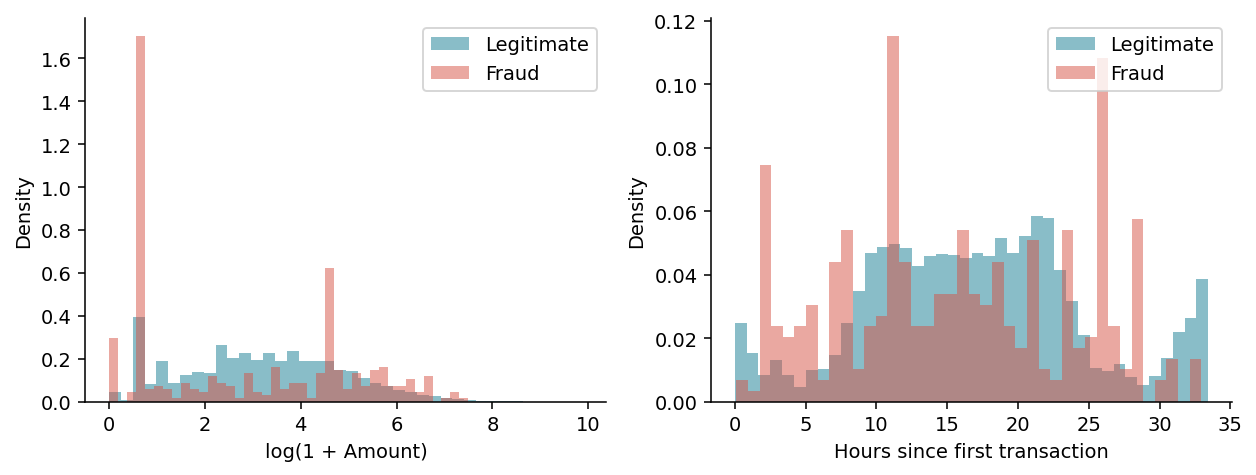

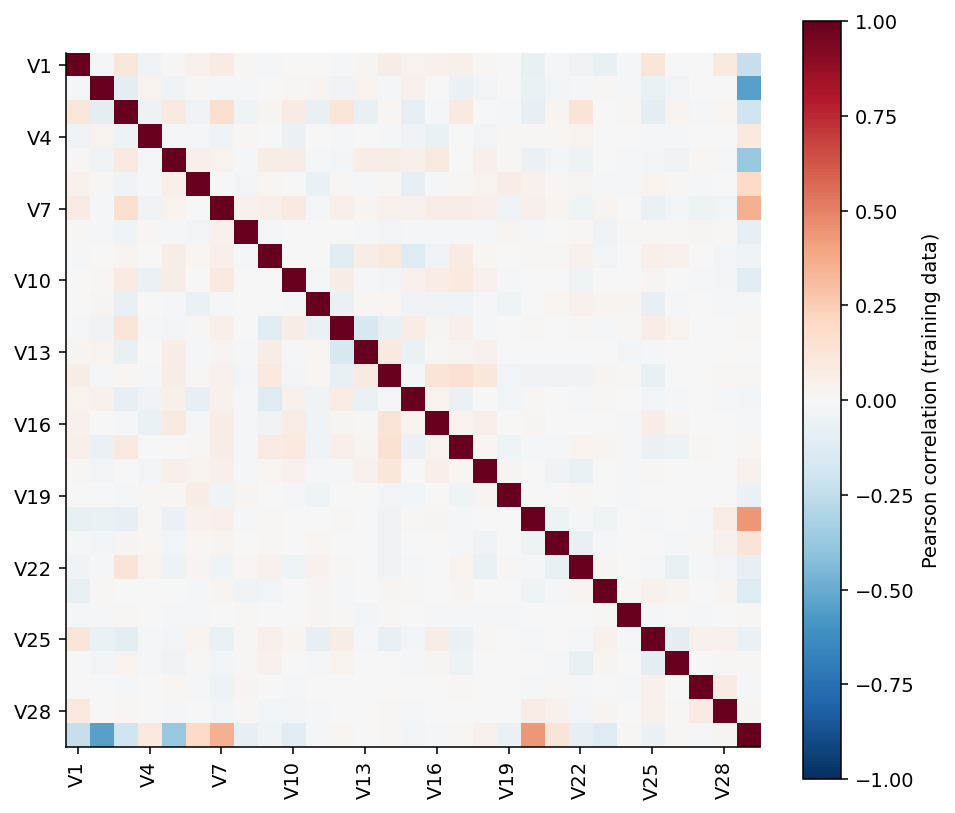

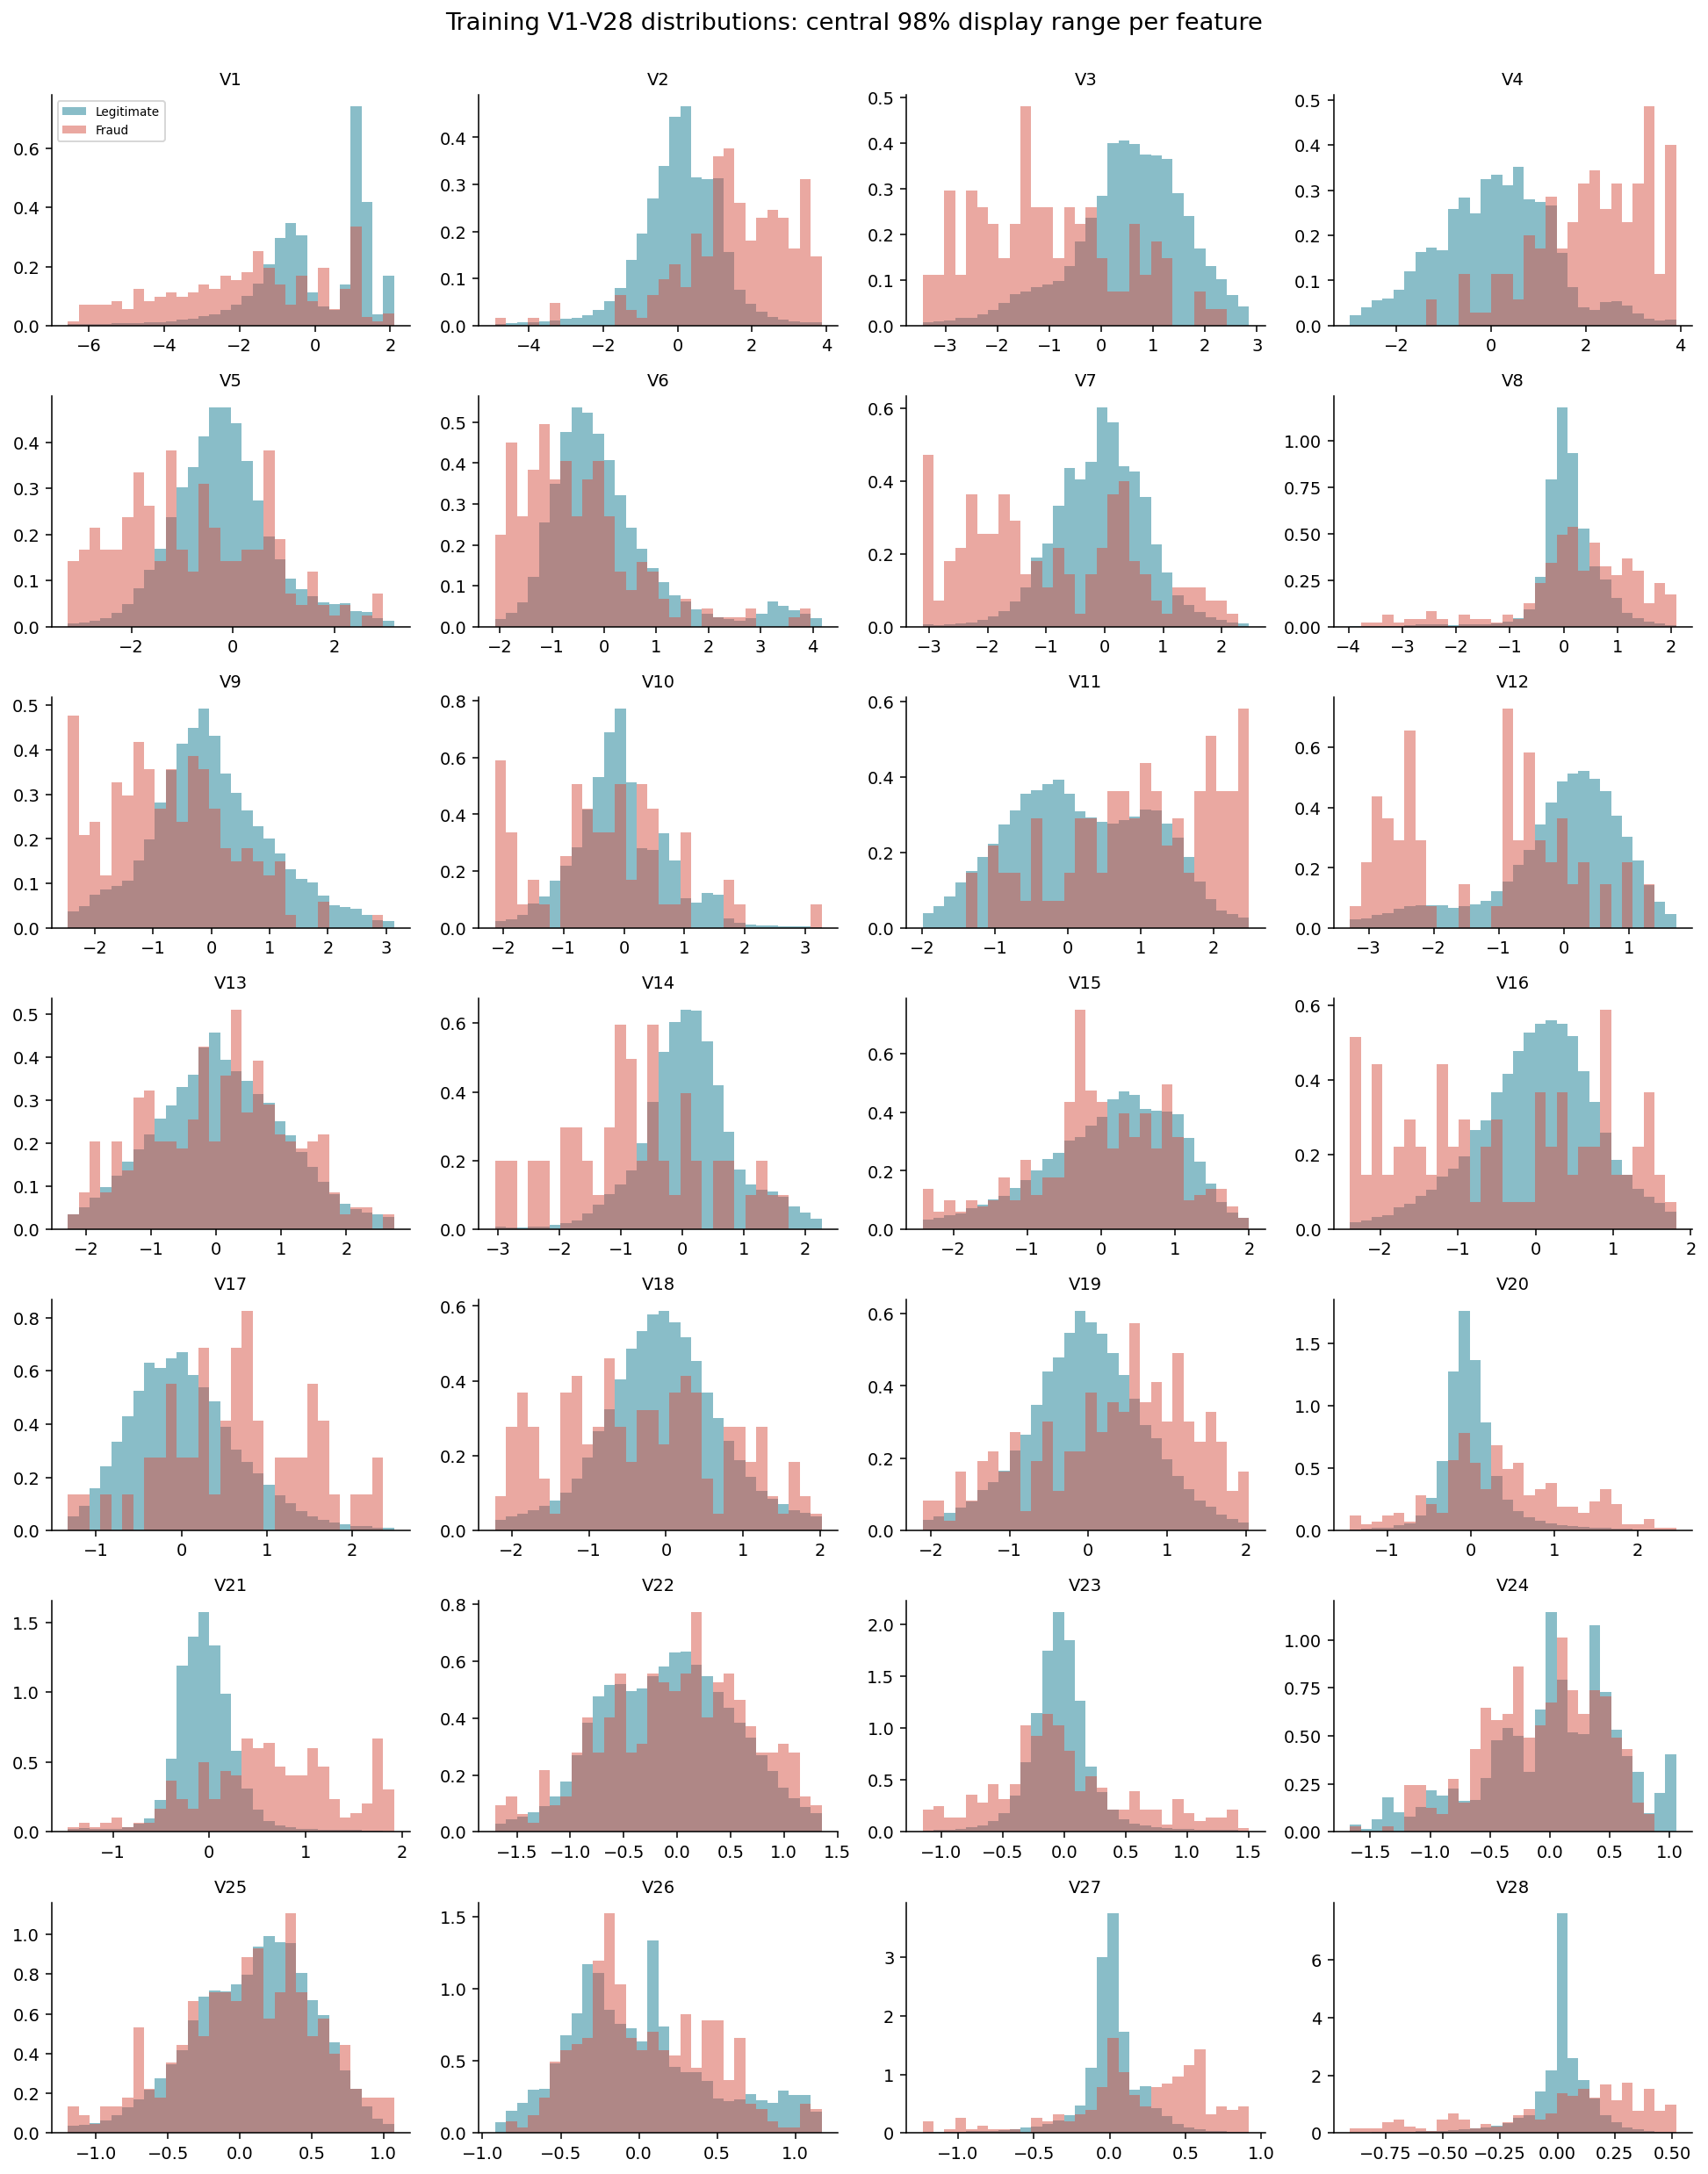

In [4]:
figure('eda_class_imbalance.png')
figure('eda_amount_time.png')
figure('eda_correlation.png')
figure('eda_v_distributions.png')

## Quality interpretation
The CSV has no missing/non-finite cells and 1,081 exact duplicates. They are retained because transaction identifiers are absent. Equal Time values stay together, preventing exact duplicates spanning splits. V distribution panels show the central 98% training range per feature; extreme values remain in model fitting. The released PCA features cannot be independently refitted.